# Swin-T for 120 dog breeds: fine-tuning and evaluation

ITRI626 group project. **Model family 3 of 3: Swin Transformer** (Sulaiman).
Lindani trains a small CNN from scratch, JP trains EfficientNetV2-S, and this notebook covers Swin-T, pretrained on ImageNet-1K and fine-tuned on Stanford Dogs.

The work itself lives in four scripts in this folder. The notebook runs their checks and shows their saved results, so there is one copy of the code:

| Step | Script | What it does |
|---|---|---|
| 1 | `dataset.py` | Reads the shared 70/15/15 split (seed 42), augmentation for training only |
| 2 | `model.py` | Swin-T with ImageNet weights, last layer replaced by a 120-breed head |
| 3 | `train.py` | Fine-tunes the model, logs every setting, keeps the best epoch |
| 5 | `evaluate.py` | Scores validation, then the test set once; writes all metrics and figures |

Training takes about 19 minutes on an RTX 4060 Laptop GPU, so it is run from the terminal (`python Sulaiman_Model/train.py`) rather than inside this notebook. Section 4 shows its saved log.

In [1]:
import csv, json, sys
from pathlib import Path
from IPython.display import Image, display

import torch, torchvision, numpy, matplotlib

HERE = Path.cwd() if (Path.cwd() / "dataset.py").exists() else Path.cwd() / "Sulaiman_Model"
sys.path.insert(0, str(HERE))
RUN = HERE / "results" / "runs" / "swin_t"

print("python      ", sys.version.split()[0])
print("torch       ", torch.__version__)
print("torchvision ", torchvision.__version__)
print("numpy       ", numpy.__version__)
print("matplotlib  ", matplotlib.__version__)
print("cuda        ", torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

python       3.14.5
torch        2.11.0+cu128
torchvision  0.26.0+cu128
numpy        2.5.2
matplotlib   3.11.2


cuda         True NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Data: the shared split

The same split file is used by all three models: 14,355 training, 3,025 validation and 3,200 test photos across 120 breeds, seed 42. The self-test confirms every photo exists, the labels match the breed folders, and the clean test set (34 photos with a near-copy in training removed, from Lindani's duplicate check) has 3,166 photos.

**Preprocessing**: resize to 224 x 224, ImageNet normalisation. **Augmentation, training only**: horizontal flip, rotation up to 15 degrees, mild colour jitter. No vertical flips, because dogs are photographed upright.

In [2]:
import dataset
dataset.main()

SELF-TEST

  torch                              2.11.0+cu128
  cuda available                     True
  gpu                                NVIDIA GeForce RTX 4060 Laptop GPU, 8.0 GB

  images_dir                         C:\Github\Dog_Classifier\archive\images\Images
  split_file                         C:\Github\Dog_Classifier\Sulaiman_Model\split_manifest.json
  classes                            120
  train_photographs                  14355
  val_photographs                    3025
  test_photographs                   3200
  leaked_test_photographs_excluded   0
  batch_size                         8
  input_size                         224
  seed                               42



  photos missing on this machine     0
  first three breeds                 ['Chihuahua', 'Japanese Spaniel', 'Maltese Dog']
  last breed                         African Hunting Dog



  one training batch
    images                           (8, 3, 224, 224)
    labels                           [57, 106, 73, 79, 59, 92, 92, 87]
    first photograph                 n02099712-Labrador_retriever/n02099712_3980.jpg
    pixel values                     -2.12 to 2.64

  label check                        folder n02099712-Labrador_retriever -> Labrador Retriever

  full test set                      3200
  clean test set                     3166 (34 leaked photos excluded)

Self-test passed.


## 2. Model: Swin-T with a new head

**Transfer learning.** The backbone keeps its ImageNet-1K weights (`Swin_T_Weights.IMAGENET1K_V1`). The original 1,000-class head is replaced by Dropout(0.3) + Linear(768 to 120). The whole network is fine-tuned; nothing is frozen.

**How Swin works.** The image is cut into 4 x 4 pixel patches. Self-attention lets each patch compare itself with other patches, but only inside 7 x 7-patch windows, which keeps the cost linear in image size. Every second block the windows shift by half a window, so information crosses window borders. Patches are merged between stages (56, 28, 14, 7 patches across), giving a CNN-like hierarchy.

In [3]:
import model
model.main()

SELF-TEST



  model                    Swin-T (swin_t), torchvision
  pretrained weights       Swin_T_Weights.IMAGENET1K_V1
  new head                 Dropout(0.3) -> Linear(768 -> 120)
  total parameters         27,611,634
  trainable parameters     27,611,634
  of which the new head    92,280
  backbone (pretrained)    27,519,354



  device                   cuda
  input shape              (2, 3, 224, 224)   (2 photos, 3 colours, 224 x 224)
  output shape             (2, 120)   (2 photos, one score per breed)
  GPU memory in use        116 MB

Self-test passed.


## 3. Training settings

Read from the run's own record (`run_config.json`), written automatically by `train.py`. Everything shared with the other two models (split, input size, augmentation, normalisation, seed, loss, metrics) is identical. Learning rate, warm-up, weight decay, batch size and epoch budget differ because a pretrained transformer needs different settings from a CNN trained from scratch.

In [4]:
config = json.loads((RUN / "run_config.json").read_text(encoding="utf-8"))
keys = ["model", "pretrained_weights", "transfer_learning", "total_parameters",
        "input_size", "batch_size", "optimiser", "learning_rate", "schedule",
        "weight_decay", "dropout", "gradient_clipping_max_norm", "loss",
        "label_smoothing", "epochs_planned", "early_stopping", "epochs_run",
        "best_epoch", "best_val_macro_f1", "mixed_precision", "seed", "total_minutes"]
config["batch_size"] = config["data"]["batch_size"]
for k in keys:
    print(f"{k:<28} {config.get(k)}")
print()
for k, v in config["environment"].items():
    print(f"{k:<28} {v}")

model                        Swin-T (Swin Transformer Tiny), torchvision swin_t
pretrained_weights           Swin_T_Weights.IMAGENET1K_V1
transfer_learning            new head Dropout + Linear(768 -> 120); whole network fine-tuned, nothing frozen
total_parameters             27611634
input_size                   224
batch_size                   32
optimiser                    AdamW
learning_rate                0.0001
schedule                     linear warm-up over 1.0 epoch(s), then cosine decay to 0, updated every batch
weight_decay                 0.05
dropout                      0.3
gradient_clipping_max_norm   1.0
loss                         CrossEntropyLoss
label_smoothing              0.0
epochs_planned               15
early_stopping               validation macro F1, patience 4
epochs_run                   15
best_epoch                   15
best_val_macro_f1            0.86441
mixed_precision              True
seed                         42
total_minutes                19.0

## 4. Training history

One row per epoch from `metrics.csv`. Validation macro F1 rose quickly (0.757 after epoch 1, because the backbone already knew what dogs look like) and was flat from about epoch 12. The 15-epoch cap was reached, but the last four epochs added only 0.001.

Validation accuracy is above training accuracy for the first epochs because training accuracy is measured with augmentation and dropout switched on, while the model is still changing. The later gap (97.7 against 86.6 per cent) is mild overfitting.

epoch  train loss  train acc  val loss  val acc  val F1
    1       3.086     33.17%     0.714   77.09%  0.7568
    2       0.980     72.32%     0.555   81.85%  0.8088
    3       0.741     78.12%     0.560   81.75%  0.8095
    4       0.596     82.07%     0.513   83.54%  0.8316
    5       0.484     85.45%     0.514   84.26%  0.8393
    6       0.392     88.17%     0.553   83.77%  0.8328
    7       0.329     90.11%     0.563   84.03%  0.8379
    8       0.257     92.18%     0.524   84.93%  0.8482
    9       0.207     93.66%     0.519   85.26%  0.8496
   10       0.167     95.29%     0.535   86.22%  0.8595
   11       0.140     96.09%     0.530   86.15%  0.8600
   12       0.117     96.89%     0.539   86.45%  0.8631
   13       0.107     97.28%     0.537   86.48%  0.8626
   14       0.100     97.32%     0.533   86.48%  0.8629
   15       0.093     97.72%     0.533   86.61%  0.8644


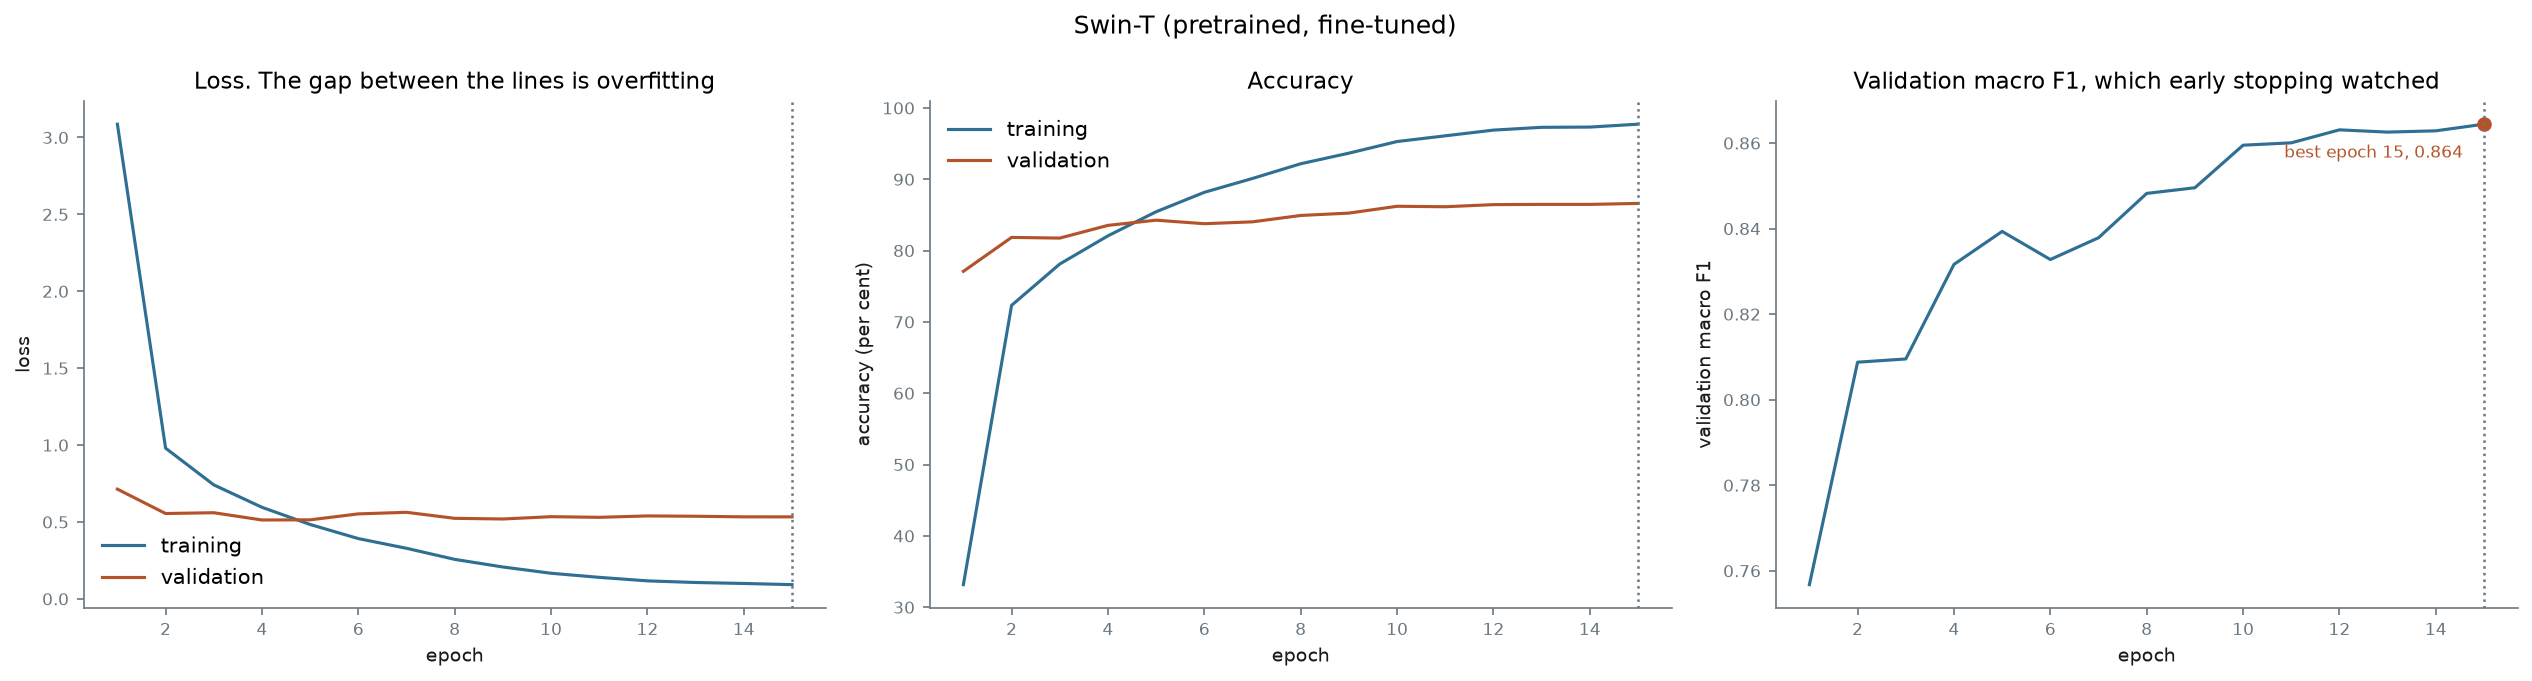

In [5]:
with open(RUN / "metrics.csv", newline="", encoding="utf-8") as f:
    history = list(csv.DictReader(f))
print(f"{'epoch':>5} {'train loss':>11} {'train acc':>10} {'val loss':>9} {'val acc':>8} {'val F1':>7}")
for r in history:
    print(f"{r['epoch']:>5} {float(r['train_loss']):>11.3f} {100*float(r['train_accuracy']):>9.2f}% "
          f"{float(r['val_loss']):>9.3f} {100*float(r['val_accuracy']):>7.2f}% {float(r['val_macro_f1']):>7.4f}")
display(Image(filename=str(RUN / "eval_test" / "fig_curves.png")))

## 5. Results on validation and test

`evaluate.py` scored validation first, then the test set exactly once (`--final`). Test is about 1 point below validation with overlapping confidence intervals, so the model was not accidentally tuned to the validation set.

In [6]:
for split in ("val", "test"):
    print((RUN / f"eval_{split}" / "metrics_summary.txt").read_text(encoding="utf-8"))

EVALUATION OF SWIN_T ON THE VAL SET
Weights                  epoch 15 (validation macro F1 0.8644 when trained)
Parameters               27,611,634
Photographs scored       3025
Breeds                   120, chance level 0.83 per cent

HEADLINE
  Accuracy               86.61 per cent (95 per cent interval 85.35 to 87.78)
  Top-5 accuracy         98.88 per cent
  Macro F1               0.8644
  Macro precision        0.8685
  Macro recall           0.8649
  Weighted F1            0.8650

STRONGEST BREEDS BY F1
  Weimaraner                         F1 1.000  (24 photographs)
  Bedlington Terrier                 F1 1.000  (27 photographs)
  Scotch Terrier                     F1 1.000  (23 photographs)
  Keeshond                           F1 1.000  (23 photographs)
  Brabancon Griffon                  F1 1.000  (22 photographs)

WEAKEST BREEDS BY F1
  Eskimo Dog                         F1 0.455  (22 photographs)
  Siberian Husky                     F1 0.531  (28 photographs)
  Collie       

## 6. Confusion matrix

The full 120 x 120 matrix (rows normalised): a strong diagonal with a few off-diagonal clusters, which are groups of look-alike breeds. The close-up shows the 15 weakest breeds.

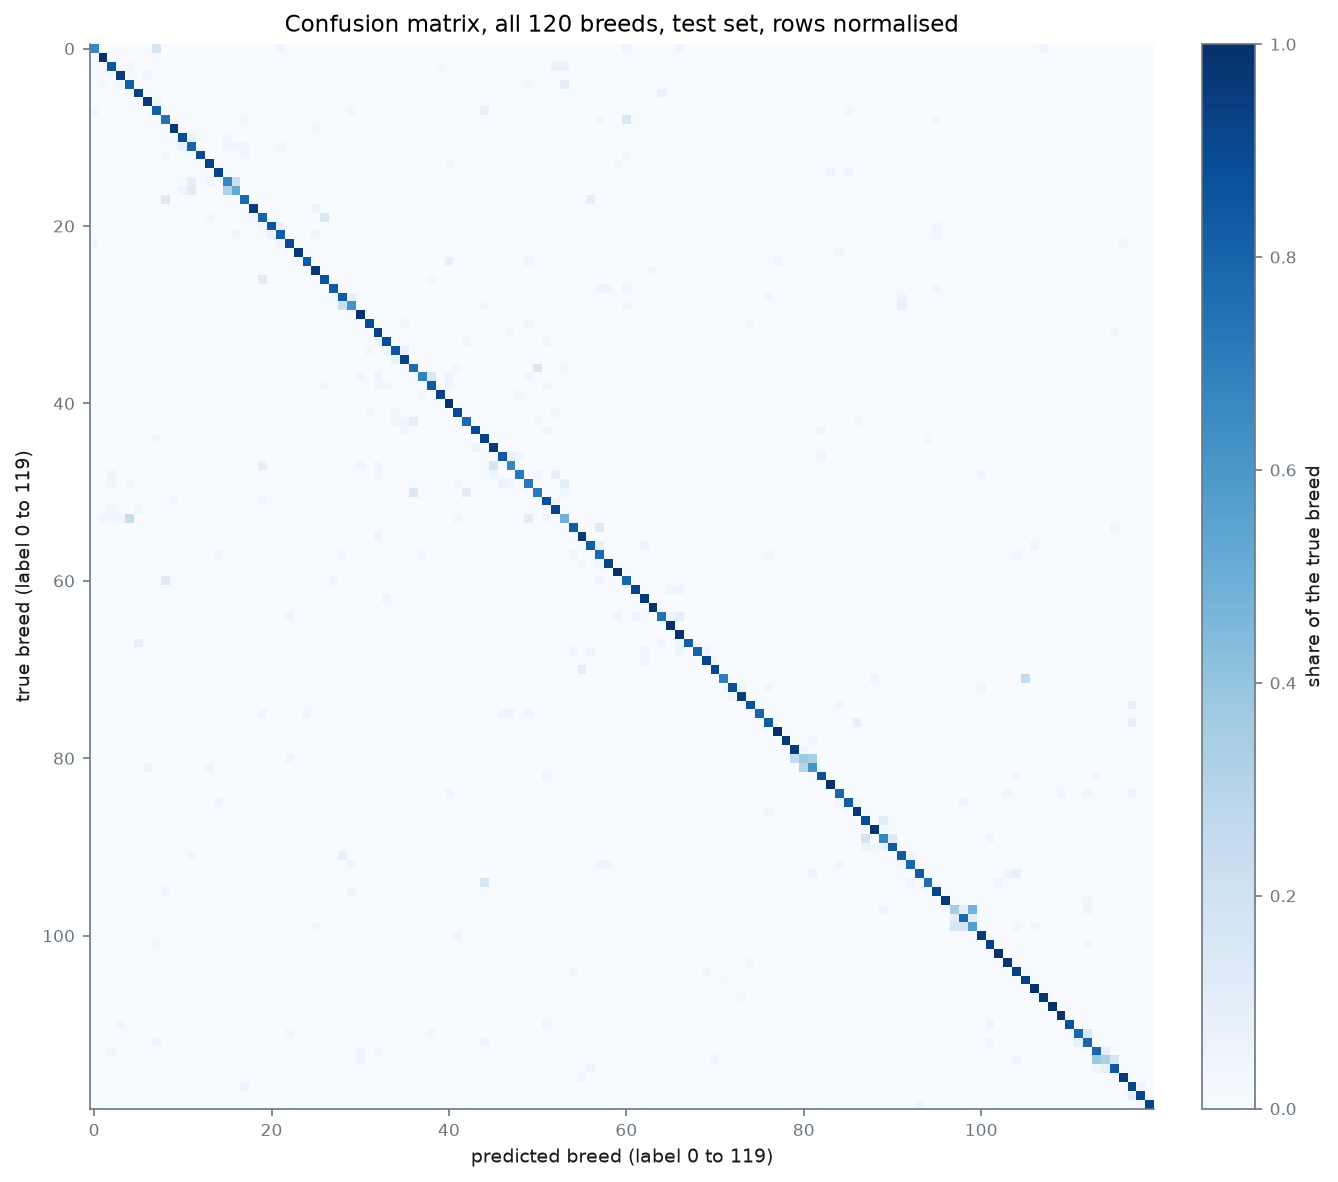

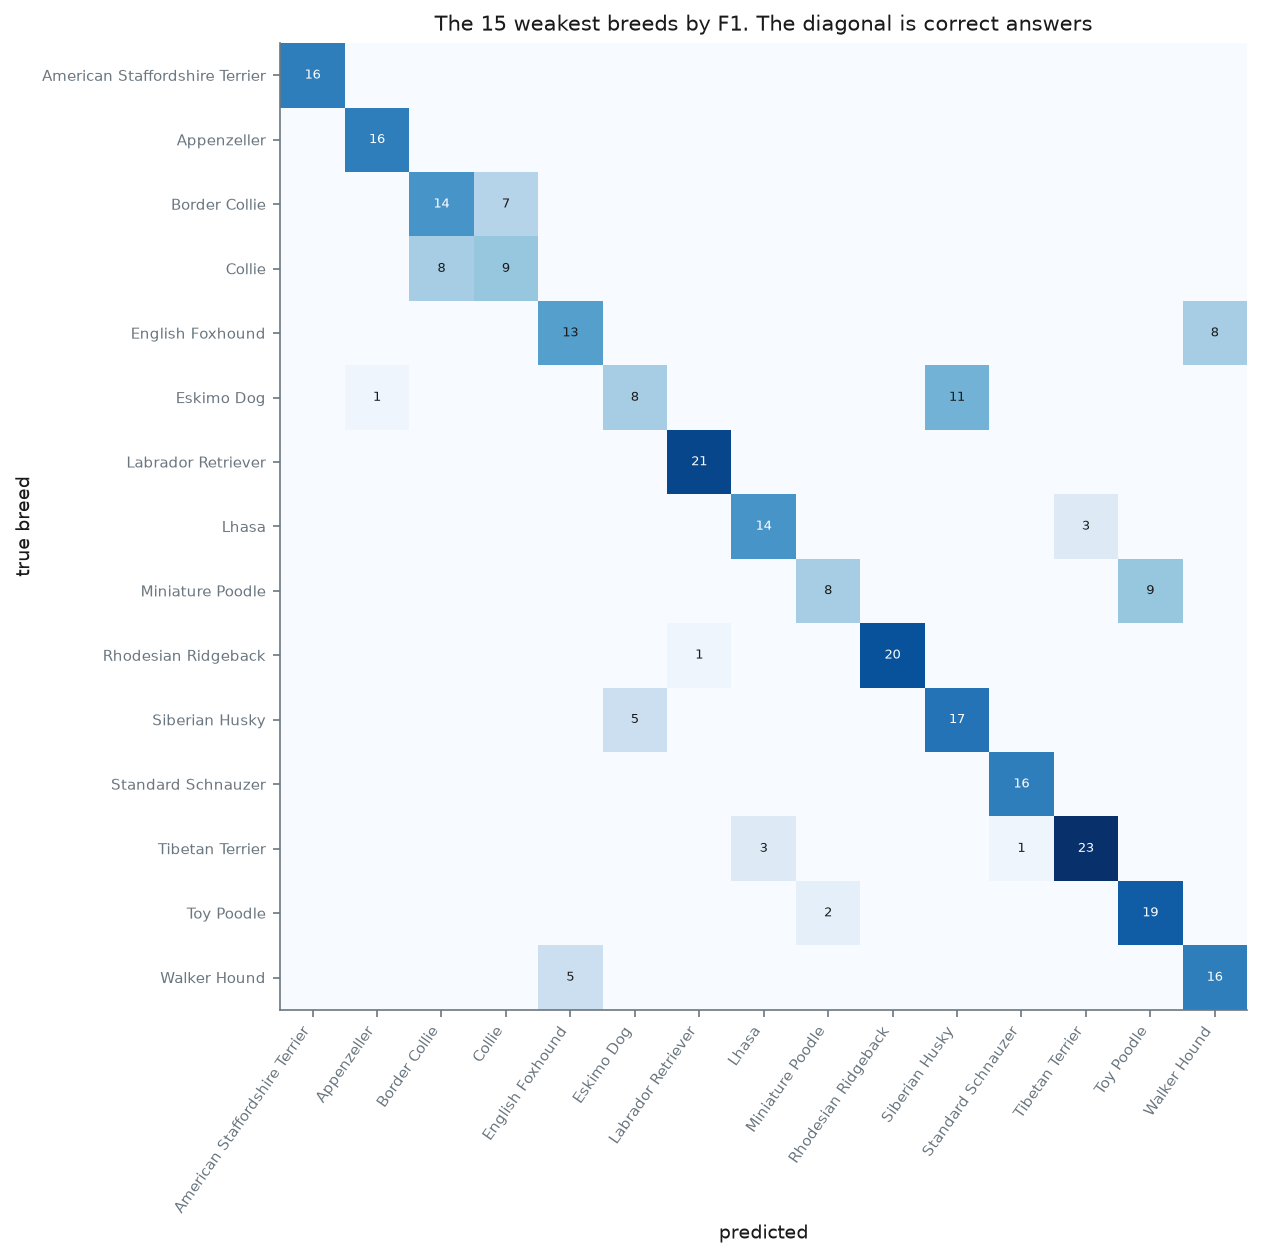

In [7]:
display(Image(filename=str(RUN / "eval_test" / "fig_confusion_full.png")))
display(Image(filename=str(RUN / "eval_test" / "fig_confusion_worst.png")))

## 7. Per-breed metrics (test set)

All 120 breeds are in `eval_test/per_class_metrics.csv`. The ten weakest and ten strongest are shown here.

In [8]:
with open(RUN / "eval_test" / "per_class_metrics.csv", newline="", encoding="utf-8") as f:
    per_class = list(csv.DictReader(f))
ranked = sorted(per_class, key=lambda r: float(r["f1"]))
def show(rows, title):
    print(title)
    print(f"  {'breed':<32} {'precision':>9} {'recall':>7} {'F1':>6} {'photos':>7}")
    for r in rows:
        print(f"  {r['breed']:<32} {float(r['precision']):>9.3f} {float(r['recall']):>7.3f} "
              f"{float(r['f1']):>6.3f} {r['support']:>7}")
    print()
show(ranked[:10], "WEAKEST 10")
show(ranked[-10:][::-1], "STRONGEST 10")

WEAKEST 10
  breed                            precision  recall     F1  photos
  Eskimo Dog                           0.500   0.348  0.410      23
  Collie                               0.529   0.375  0.439      24
  Miniature Poodle                     0.667   0.333  0.444      24
  Lhasa                                0.583   0.483  0.528      29
  Siberian Husky                       0.548   0.567  0.557      30
  English Foxhound                     0.650   0.520  0.578      25
  Border Collie                        0.583   0.609  0.596      23
  Walker Hound                         0.615   0.667  0.640      24
  American Staffordshire Terrier       0.762   0.615  0.681      26
  Appenzeller                          0.696   0.667  0.681      24

STRONGEST 10
  breed                            precision  recall     F1  photos
  Chow                                 1.000   1.000  1.000      30
  Pug                                  0.968   1.000  0.984      30
  Norwegian Elkhound   

## 8. Correct and incorrect predictions

Most confident first. Several of the most confident "mistakes" look like **label errors in the dataset** rather than model errors: for example, a photo labelled French Bulldog that shows a Boston Terrier, and a photo labelled Schipperke that shows a much larger Groenendael.

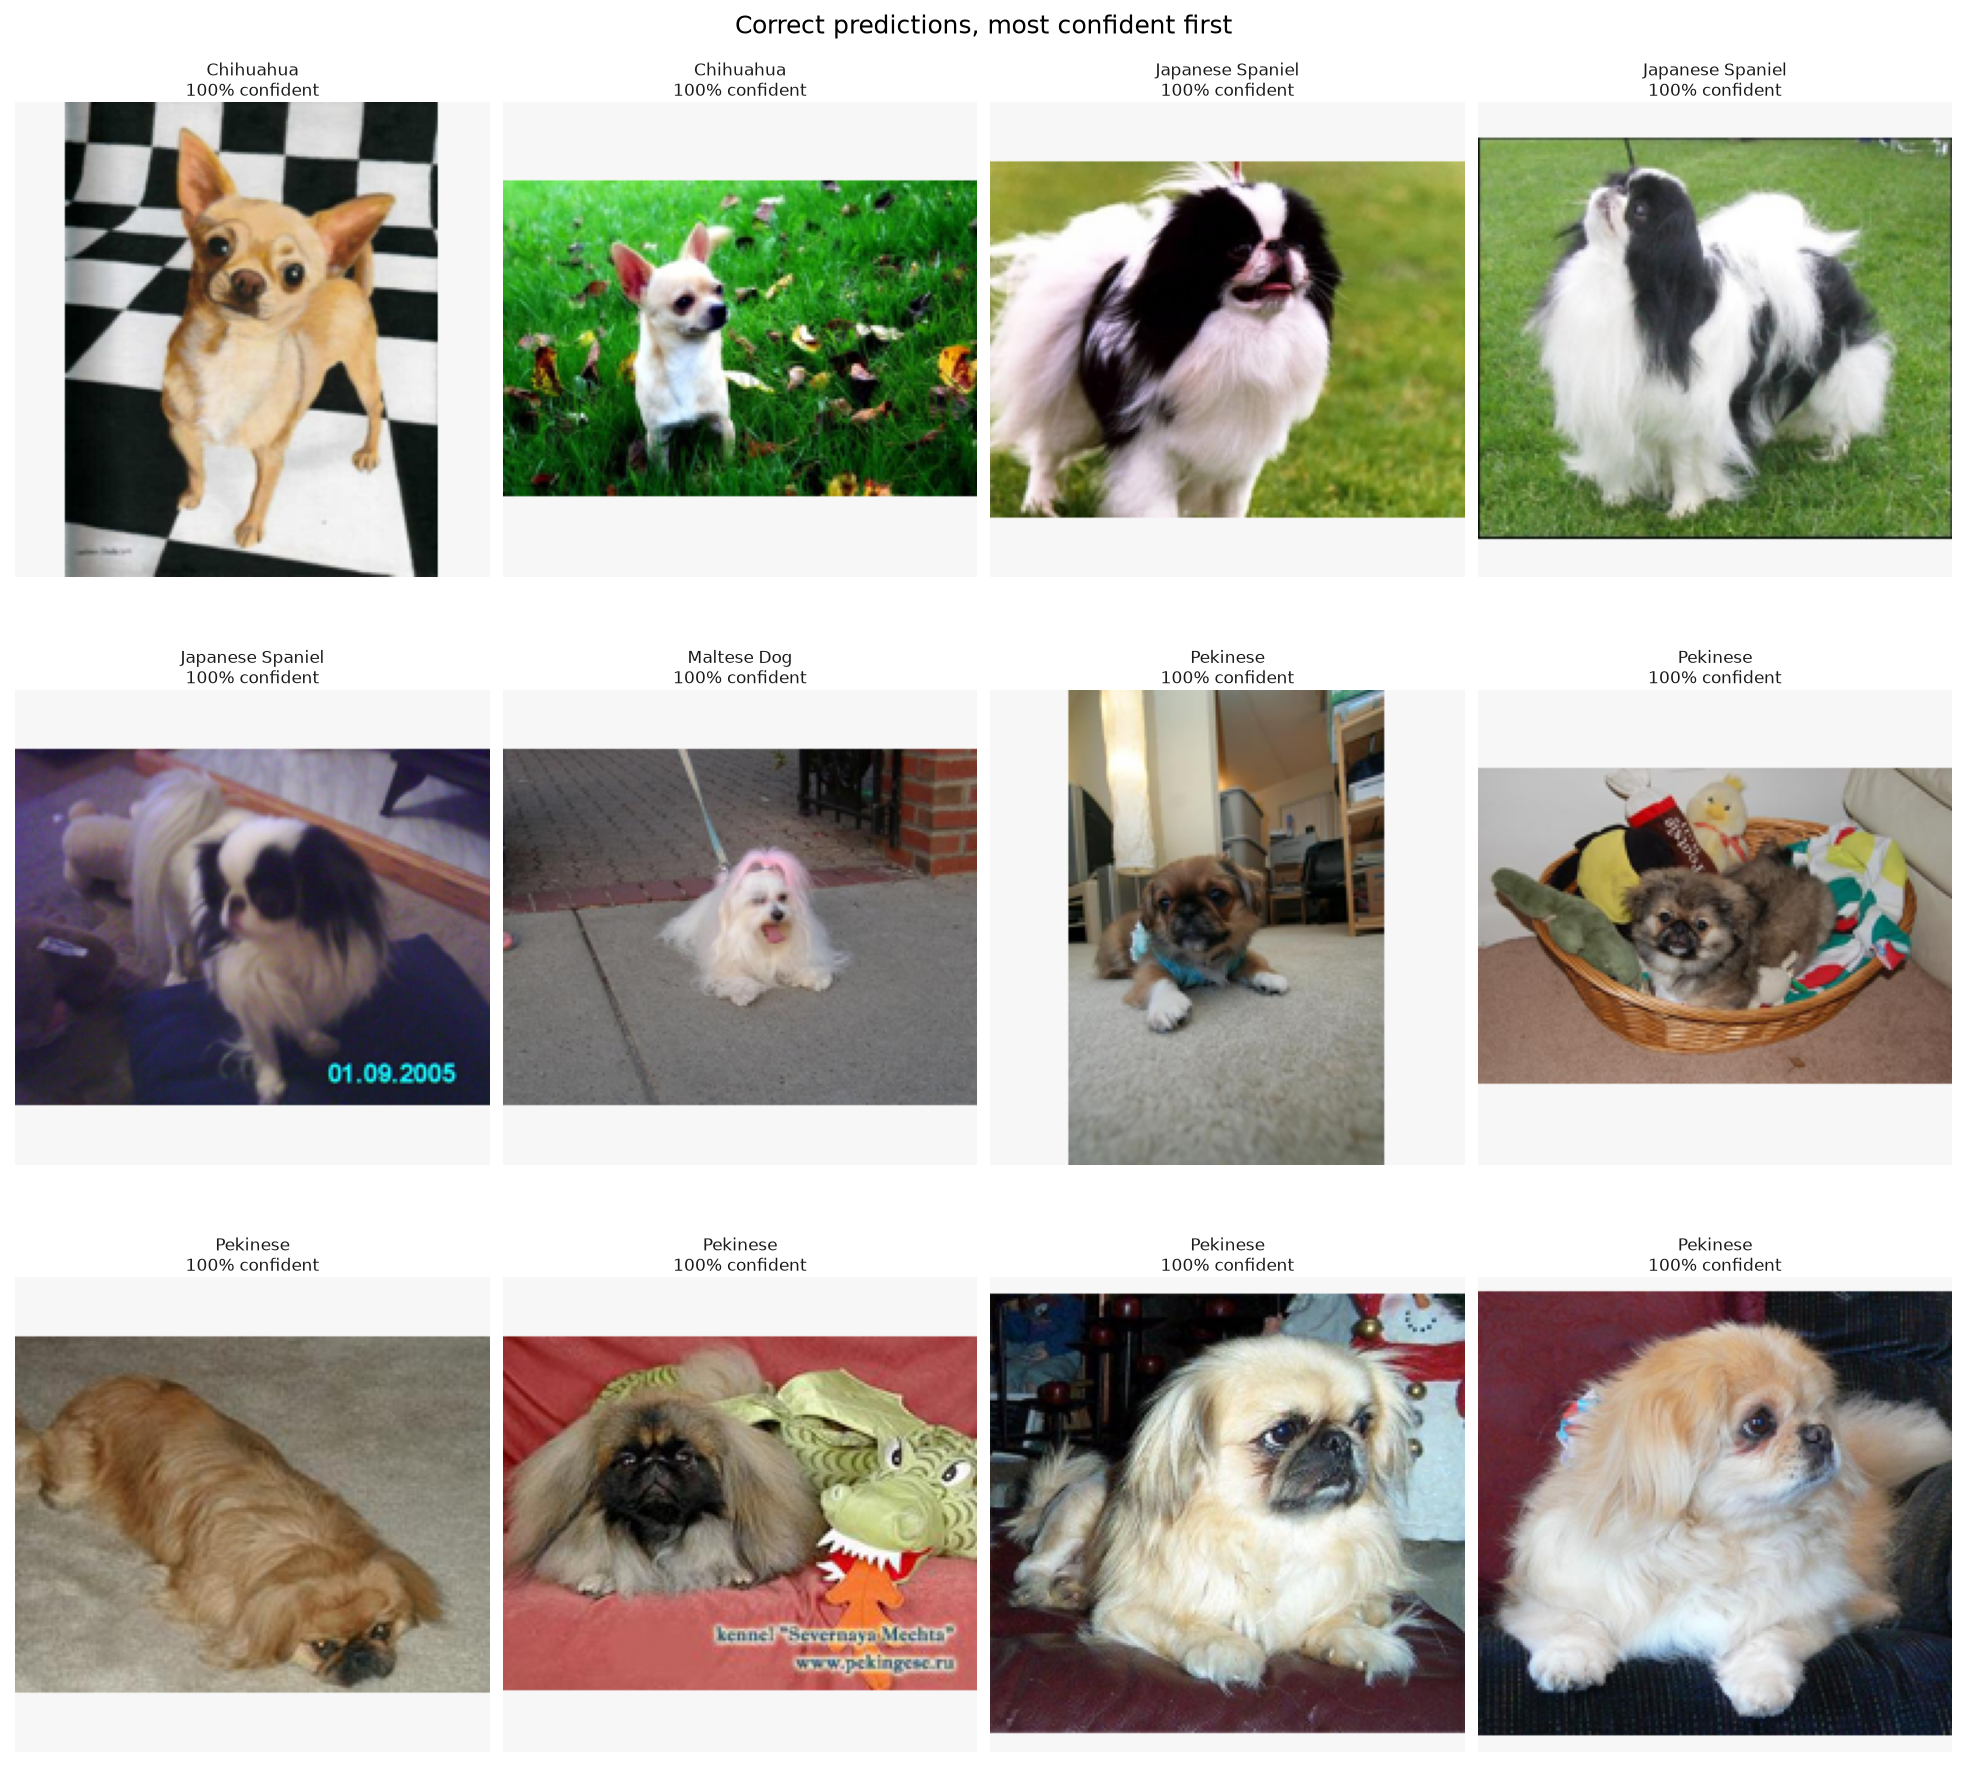

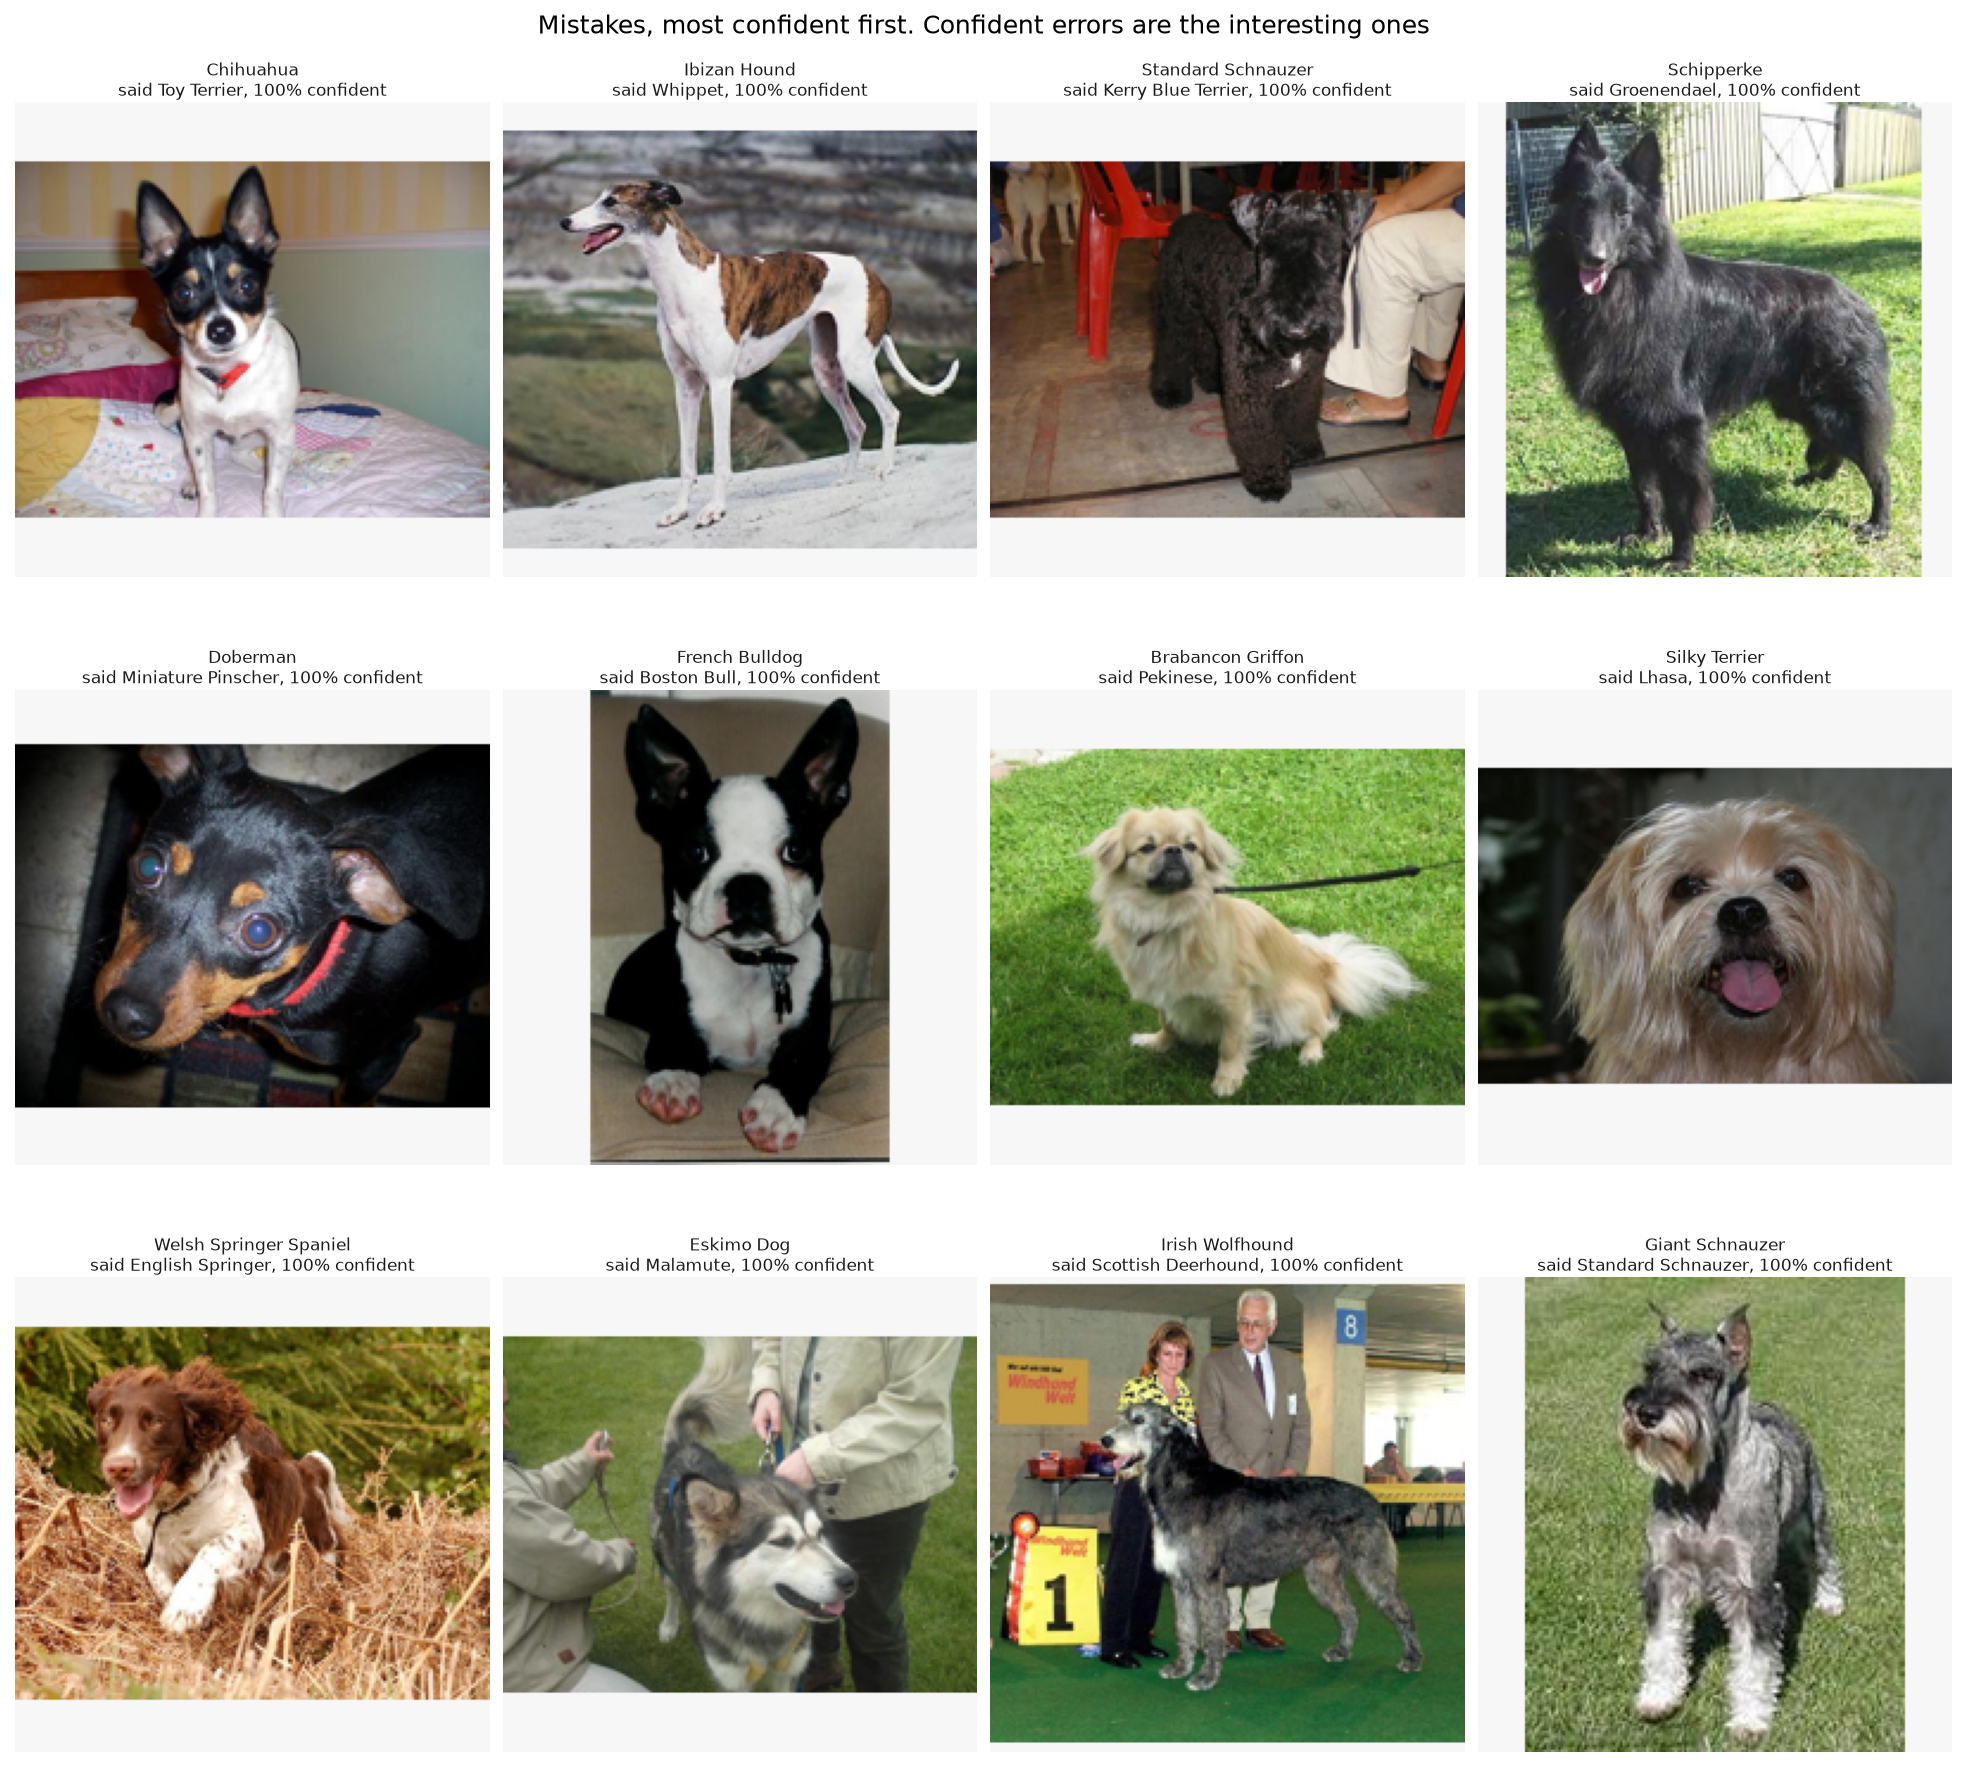

In [9]:
display(Image(filename=str(RUN / "eval_test" / "fig_correct.png")))
display(Image(filename=str(RUN / "eval_test" / "fig_wrong.png")))

## 9. Leakage check

Lindani's duplicate check found 34 test photos with a near-copy in training. The clean test score leaves them out. The cell below looks at what the model did on those 34.

In [10]:
leaked_path = HERE.parent / "Lindani_Model" / "results" / "duplicate_check" / "leaked_photos.csv"
with open(leaked_path, newline="", encoding="utf-8") as f:
    leaked = {r["photo"]: r for r in csv.DictReader(f) if r["pile"] == "test"}
with open(RUN / "eval_test" / "predictions.csv", newline="", encoding="utf-8") as f:
    pred = {r["photo"]: r for r in csv.DictReader(f)}

same = [k for k in leaked if leaked[k]["same_breed"] == "True"]
diff = [k for k in leaked if leaked[k]["same_breed"] != "True"]
right = lambda keys: sum(pred[k]["correct"] == "True" for k in keys)
print(f"Leaked test photos: {len(leaked)}")
print(f"  training copy has the SAME breed label:      {right(same)} of {len(same)} correct")
print(f"  training copy has a DIFFERENT breed label:   {right(diff)} of {len(diff)} correct")
print()
for k in diff:
    print(f"  labelled {pred[k]['true_breed']:<24} copy in training labelled "
          f"{leaked[k]['copy_breed'].split('-',1)[1]:<22} model said {pred[k]['predicted_breed']}")

metrics = json.loads((RUN / "eval_test" / "metrics.json").read_text(encoding="utf-8"))
print(f"\nFull test  {100*metrics['accuracy']:.2f}%   clean test {100*metrics['clean_test']['accuracy']:.2f}%")

Leaked test photos: 34
  training copy has the SAME breed label:      25 of 25 correct
  training copy has a DIFFERENT breed label:   0 of 9 correct

  labelled Walker Hound             copy in training labelled English_foxhound       model said English Foxhound
  labelled Giant Schnauzer          copy in training labelled standard_schnauzer     model said Standard Schnauzer
  labelled Standard Schnauzer       copy in training labelled miniature_schnauzer    model said Miniature Schnauzer
  labelled Schipperke               copy in training labelled groenendael            model said Groenendael
  labelled Collie                   copy in training labelled Border_collie          model said Border Collie
  labelled Bernese Mountain Dog     copy in training labelled Appenzeller            model said Appenzeller
  labelled Eskimo Dog               copy in training labelled Siberian_husky         model said Siberian Husky
  labelled Eskimo Dog               copy in training labelled Siberia

**Reading it.** On the 25 leaked photos whose training copy has the same label, the model is always right. On the 9 whose training copy carries a different breed label, it is always wrong, and each time it gives exactly the training copy's label. The model recalls photos it trained on; the two effects roughly cancel, which is why the clean and full scores are almost equal. It also shows that part of the measured error is the dataset's own label noise.

A larger caveat cannot be measured here: Stanford Dogs was built from ImageNet, and Swin-T was pretrained on ImageNet-1K, so the backbone has very likely seen many of these exact photos before. Part of the gap between Swin-T and Lindani's scratch CNN reflects that.

## 10. Summary

| | Validation | Test | Clean test |
|---|---|---|---|
| Accuracy | 86.61 % | 85.38 % | 85.50 % |
| Top-5 accuracy | 98.88 % | 98.56 % | |
| Macro F1 | 0.8644 | 0.8490 | 0.8500 |

Main errors are look-alike breed pairs (Eskimo Dog and Siberian Husky, Collie and Border Collie, Miniature and Toy Poodle, Lhasa and Shih-Tzu), the same pairs Lindani's CNN struggles with, which points to the data rather than the architecture.